# Campos Vetoriais – Notebook Organizado
_Organizado em 2025-10-01 16:53:38_

> Este notebook foi limpo (saídas removidas), células vazias excluídas e metadados padronizados. Um sumário automático foi inserido abaixo.


## Table of Contents

- [Matemática Simbólica](#matemática-simbólica)
- [Ver o campo com matplotlib](#ver-o-campo-com-matplotlib)
- [Plano $y=1$](#plano-$y=1$)
- [Plano $x=1$](#plano-$x=1$)
- [Rotacional](#rotacional)


# Matemática Simbólica

In [1]:
import sympy as sp

# Symbols
x, y, z = sp.symbols('x y z')

# Vector field v(x,y) = <4x^2 y^3, 2x^2 y^3, x y>
ax = 4*x**2*y**3
ay = -2*x**2*y**3
az = x*y

# Divergence: ∂v1/∂x + ∂v2/∂y + ∂v3/∂z
div_v = sp.diff(ax, x) + sp.diff(ay, y) + sp.diff(az, z)
div_v

-6*x**2*y**2 + 8*x*y**3

In [2]:
# Curl (rotacional): <∂v3/∂y - ∂v2/∂z, ∂v1/∂z - ∂v3/∂x, ∂v2/∂x - ∂v1/∂y>
curl_v = sp.Matrix([
    sp.diff(az, y) - sp.diff(ay, z),
    sp.diff(ax, z) - sp.diff(az, x),
    sp.diff(ay, x) - sp.diff(ax, y)
])

curl_v

Matrix([
[                       x],
[                      -y],
[-12*x**2*y**2 - 4*x*y**3]])

# Ver o campo com matplotlib

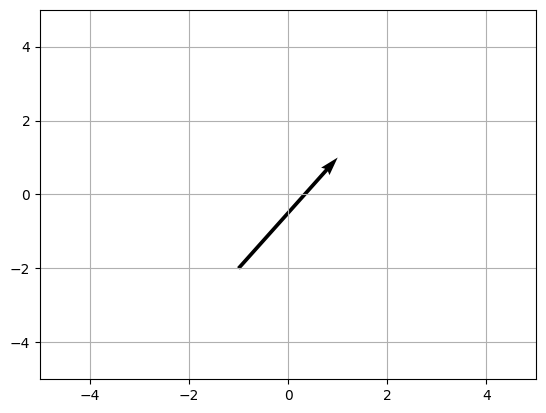

In [3]:
import matplotlib.pyplot as plt
import numpy as np
vetor = np.array([2, 3])
plt.quiver(-1,-2, vetor[0], vetor[1], scale_units='xy', angles='xy', scale=1)
plt.xlim(-5,5)
plt.ylim(-5,5)
plt.grid()

In [4]:
# Domain (choose a modest range to avoid very large arrows)
x = np.linspace(-1.2, 1.2, 21)
y = np.linspace(-1.2, 1.2, 21)
X, Y = np.meshgrid(x, y)

# Components of the vector field
U = 4 * X**2 * Y**3   # v1(x,y)
V = -2 * X**2 * Y**3   # v2(x,y)
W = X * Y             # v3(x,y)

In [5]:
# 3D quiver with Plotly (Cone) for v(x,y) = <4x^2 y^3, 2x^2 y^3, x y>
# Comments in English.

import numpy as np
import plotly.graph_objects as go

# Grid (keep modest range to avoid huge cones)
x = np.linspace(-1.2, 1.2, 17)
y = np.linspace(-1.2, 1.2, 17)
X, Y = np.meshgrid(x, y)
Z = np.zeros_like(X)

# Vector field components
U = 4 * X**2 * Y**3
V = -2 * X**2 * Y**3
W = X * Y

# Optional: scale vectors for legibility (like Matplotlib length=1/scale)
L = np.sqrt(U**2 + V**2 + W**2)
max_L = L.max() if L.size > 0 else 1.0
scale = 0.9 * max_L
U_plot = U / scale
V_plot = V / scale
W_plot = W / scale

fig = go.Figure(data=go.Cone(
    x=X.ravel(), y=Y.ravel(), z=Z.ravel(),          # cone bases on z=0
    u=U_plot.ravel(), v=V_plot.ravel(), w=W_plot.ravel(),  # vector components
    colorscale="Viridis",
    showscale=True,
    sizemode="absolute",     # use absolute size (more predictable)
    sizeref=0.25,            # tweak arrow length; smaller -> longer arrows
    anchor="tail"            # place the cone tail at (x,y,z)
))

# Axes & layout
fig.update_layout(
    title="3D quiver (Plotly Cone) of v(x,y) = <4x^2 y^3, -2x^2 y^3, x y> on z=0",
    scene=dict(
        xaxis_title="x",
        yaxis_title="y",
        zaxis_title="z",
        aspectmode="manual",
        aspectratio=dict(x=1, y=1, z=0.5)  # similar to set_box_aspect((1,1,0.5))
    ),
    margin=dict(l=0, r=0, t=40, b=0)
)

fig.show()


In [6]:
# 3D quiver with Plotly (Cone) for v(x,y) = <4x^2 y^3, 2x^2 y^3, x y>
# Now with z varying in the same range as x and y

import numpy as np
import plotly.graph_objects as go

# Grid in 3D
x = np.linspace(-1.2, 1.2, 9)
y = np.linspace(-1.2, 1.2, 9)
z = np.linspace(-1.2, 1.2, 9)
X, Y, Z = np.meshgrid(x, y, z)

# Vector field components (note: original field does not depend on z)
U = 4 * X**2 * Y**3
V = -2 * X**2 * Y**3
W = X * Y

# Normalize for better visualization
L = np.sqrt(U**2 + V**2 + W**2)
max_L = L.max() if L.size > 0 else 1.0
scale = 0.9 * max_L
U_plot = U / scale
V_plot = V / scale
W_plot = W / scale

fig = go.Figure(data=go.Cone(
    x=X.ravel(), y=Y.ravel(), z=Z.ravel(),
    u=U_plot.ravel(), v=V_plot.ravel(), w=W_plot.ravel(),
    colorscale="Viridis",
    showscale=True,
    sizemode="absolute",
    sizeref=0.4,       # adjust to control arrow length
    anchor="tail"
))

fig.update_layout(
    title="3D quiver (Plotly Cone) of v(x,y) in full volume",
    scene=dict(
        xaxis_title="x",
        yaxis_title="y",
        zaxis_title="z",
        aspectmode="cube"
    ),
    margin=dict(l=0, r=0, t=40, b=0)
)

fig.show()


# Plano $y=1$

In [7]:
# 3D quiver with Plotly (Cone) for v(x,y) = <4x^2 y^3, -2x^2 y^3, x y>
# Now vectors plotted on the plane y = 1

import numpy as np
import plotly.graph_objects as go

# Grid (keep modest range to avoid very large cones)
x = np.linspace(-1.2, 1.2, 17)
z = np.linspace(-1.2, 1.2, 17)
X, Z = np.meshgrid(x, z)
Y = np.ones_like(X)   # Plane y = 1

# Vector field components
U = 4 * X**2 * Y**3
V = -2 * X**2 * Y**3
W = X * Y

# Scale for legibility
L = np.sqrt(U**2 + V**2 + W**2)
max_L = L.max() if L.size > 0 else 1.0
scale = 0.9 * max_L
U_plot = U / scale
V_plot = V / scale
W_plot = W / scale

# Plot with Plotly
fig = go.Figure(data=go.Cone(
    x=X.ravel(), y=Y.ravel(), z=Z.ravel(),          # base of cones on y=1 plane
    u=U_plot.ravel(), v=V_plot.ravel(), w=W_plot.ravel(),  # vector components
    colorscale="Viridis",
    showscale=True,
    sizemode="absolute",
    sizeref=0.25,
    anchor="tail"
))

# Axes & layout
fig.update_layout(
    title="3D quiver (Plotly Cone) of v(x,y) = <4x^2 y^3, -2x^2 y^3, x y> on y=1",
    scene=dict(
        xaxis_title="x",
        yaxis_title="y",
        zaxis_title="z",
        aspectmode="cube"
    ),
    margin=dict(l=0, r=0, t=40, b=0)
)

fig.show()


# Plano $x=1$

In [8]:
# Two Plotly figures: (1) vector field cones on x=1, (2) divergence surface on x=1
# Field: v(x,y) = <4x^2 y^3, -2x^2 y^3, x y>
# Divergence: div v = -6 x^2 y^2 + 8 x y^3

import numpy as np
import plotly.graph_objects as go

# --- Grid on the plane x = 1 ---
ny, nz = 17, 17     # change to 51 for smoother plots
y = np.linspace(-1.2, 1.2, ny)
z = np.linspace(-1.2, 1.2, nz)
Y, Z = np.meshgrid(y, z)
X = np.ones_like(Y)  # x = 1 everywhere

# --- Vector field evaluated at x=1 ---
U = 4 * X**2 * Y**3
V = -2 * X**2 * Y**3
W = X * Y

# Scale cones for readability (not normalization)
L = np.sqrt(U**2 + V**2 + W**2)
scale = 0.9 * L.max() if L.size else 1.0
U_plot = U / scale
V_plot = V / scale
W_plot = W / scale

# =========================
# Figure 1: cones (quiver)
# =========================
fig1 = go.Figure(go.Cone(
    x=X.ravel(), y=Y.ravel(), z=Z.ravel(),
    u=U_plot.ravel(), v=V_plot.ravel(), w=W_plot.ravel(),
    colorscale="Viridis", showscale=True,  # cone color = default magnitude proxy
    sizemode="absolute", sizeref=0.25, anchor="tail", name="vector field"
))
fig1.update_layout(
    title="Vector field on x=1 (cones)",
    scene=dict(xaxis_title="x", yaxis_title="y", zaxis_title="z", aspectmode="cube"),
    margin=dict(l=0, r=0, t=40, b=0)
)
fig1.show()

# ===================================
# Figure 2: divergence-colored plane
# ===================================
# Figure 2: divergence-colored plane with more colors
Div = -6 * (1**2) * Y**2 + 8 * (1) * Y**3   # = -6*y^2 + 8*y^3

fig2 = go.Figure(go.Surface(
    x=X, y=Y, z=Z,                       # vertical plane x=1
    surfacecolor=Div,
    colorscale="Turbo",                  # more colors than RdBu
    cmin=Div.min(), cmax=Div.max(),
    opacity=0.95,
    colorbar=dict(title="div(v) at x=1"),
    showscale=True
))
fig2.update_layout(
    title="Divergence on x=1 (surface color = div v, Turbo colormap)",
    scene=dict(xaxis_title="x", yaxis_title="y", zaxis_title="z", aspectmode="cube"),
    margin=dict(l=0, r=0, t=40, b=0)
)
fig2.show()


In [9]:
# Two Plotly figures: (1) vector field cones on y=1, (2) divergence surface on y=1
# Field: v(x,y) = <4x^2 y^3, -2x^2 y^3, x y>
# Divergence: div v = -6 x^2 y^2 + 8 x y^3

import numpy as np
import plotly.graph_objects as go

# --- Grid on the plane y = 1 ---
nx, nz = 17, 17
x = np.linspace(-1.2, 1.2, nx)
z = np.linspace(-1.2, 1.2, nz)
X, Z = np.meshgrid(x, z)
Y = np.ones_like(X)   # y = 1 everywhere

# --- Vector field evaluated at y=1 ---
U = 4 * X**2 * Y**3
V = -2 * X**2 * Y**3
W = X * Y

# Scale cones for readability
L = np.sqrt(U**2 + V**2 + W**2)
scale = 0.9 * L.max() if L.size else 1.0
U_plot = U / scale
V_plot = V / scale
W_plot = W / scale

# =========================
# Figure 1: cones (quiver)
# =========================
fig1 = go.Figure(go.Cone(
    x=X.ravel(), y=Y.ravel(), z=Z.ravel(),
    u=U_plot.ravel(), v=V_plot.ravel(), w=W_plot.ravel(),
    colorscale="Viridis", showscale=True,
    sizemode="absolute", sizeref=0.25, anchor="tail", name="vector field"
))
fig1.update_layout(
    title="Vector field on y=1 (cones)",
    scene=dict(xaxis_title="x", yaxis_title="y", zaxis_title="z", aspectmode="cube"),
    margin=dict(l=0, r=0, t=40, b=0)
)
fig1.show()

# ===================================
# Figure 2: divergence-colored plane
# ===================================
Div = -6 * X**2 * (1**2) + 8 * X * (1**3)   # = -6*x^2 + 8*x

fig2 = go.Figure(go.Surface(
    x=X, y=Y, z=Z,                       # vertical plane y=1
    surfacecolor=Div,
    colorscale="Turbo",                  # more colors
    cmin=Div.min(), cmax=Div.max(),
    opacity=0.95,
    colorbar=dict(title="div(v) at y=1"),
    showscale=True
))
fig2.update_layout(
    title="Divergence on y=1 (surface color = div v)",
    scene=dict(xaxis_title="x", yaxis_title="y", zaxis_title="z", aspectmode="cube"),
    margin=dict(l=0, r=0, t=40, b=0)
)
fig2.show()


# Rotacional

In [10]:
# Rotacional (curl) of v(x,y) on plane x=1
# v(x,y) = <4x^2 y^3, -2x^2 y^3, x y>
# curl v = <x, -y, -4xy^3 - 12x^2 y^2>

import numpy as np
import plotly.graph_objects as go

# Grid (y, z), fix x=1
ny, nz = 17, 17
y = np.linspace(-1.2, 1.2, ny)
z = np.linspace(-1.2, 1.2, nz)
Y, Z = np.meshgrid(y, z)
X = np.ones_like(Y)   # x = 1

# Curl components at x=1
Cx = X
Cy = -Y
Cz = -4*X*Y**3 - 12*X**2*Y**2   # = -4*y^3 - 12*y^2

# Plot cones of curl (no normalization)
fig = go.Figure(go.Cone(
    x=X.ravel(), y=Y.ravel(), z=Z.ravel(),
    u=Cx.ravel(), v=Cy.ravel(), w=Cz.ravel(),
    colorscale="Plasma", showscale=True,
    sizemode="scaled", sizeref=0.25, anchor="tail",
    name="curl field"
))

fig.update_layout(
    title="Rotacional (curl v) on x=1 (not normalized)",
    scene=dict(xaxis_title="x", yaxis_title="y", zaxis_title="z", aspectmode="cube"),
    margin=dict(l=0, r=0, t=40, b=0)
)

fig.show()
